## Imports & Initialization:

In [97]:
%load_ext autoreload
%autoreload 2

import os
import sys
import random
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

from knowledge_maze.tools.utils import load_json, display_usage_log
from knowledge_maze.evaluation.models.choose_models import KnowledgeMazeRunner
from knowledge_maze.evaluation.utils.preprocess import KnowledgeMazeDatasetDistiller
from knowledge_maze.evaluation.models.model_inference import KnowledgeMazeIncrementalRunner
from knowledge_maze.evaluation.models.judge_model import KnowledgeMazeIncrementalJudge

question_data = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions.json"))
hedged_question_data = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions_hedged.json"))
paragraphs = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_paragraphs.json"))

CONFIG_PATH = os.path.join(REPO_PATH, "knowledge_maze/evaluation/models/models_config.yaml")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Preliminary Reliability Assessment

Before conducting the full-scale evaluation of **CLECK**, we perform a preliminary reliability check on each model to ensure it possesses the baseline reasoning capabilities required for the benchmark.

### Methodology

* **Stratified Sampling:** We evaluate each model on a subset of **550 random samples**, stratified across our eleven reasoning operations to prevent logical type bias.
* **Reasoning Verification:** To ensure the model can handle the underlying logic of the task, we execute **three Self-Consistency (SC) rounds** for each reasoning paragraph in isolation.
* **Success Criteria:** A model is considered reliable if it achieves an **overall success rate above 90%** across all test cases.
* **General Success Metric:** Additionally, the model must maintain a **general success rate above 90%**, defined as succeeding in at least **2 out of 3 SC rounds** for any given sample.
* **Validation Goal:** This process confirms that the model’s later failures are due to the **latent conflict** rather than a fundamental inability to perform the multi-hop reasoning or the specific mathematical operations, such as counting or filtering.

---

### The "Diagnostic" Logic

By validating reasoning on isolated hops first, we establish a **capability baseline**. This allows us to argue that when a model defaults to an authoritative claim in the full benchmark, it is a behavioral "lock" rather than a lack of logical skill.

In [143]:
runner = KnowledgeMazeRunner(limit=550)
results_df = await runner.execute(question_data, paragraphs)

Model Architecture,Mean Success,General (≥2/3),Strict (3/3),Stability Profile (3 to 0)
deepseek/deepseek-v4-pro,95.2%,97.6%,88.2%,485 52 11 2
mistralai/mistral-medium-3.1,94.4%,94.5%,92.0%,506 14 12 18
meta-llama/llama-4-maverick,94.1%,95.1%,90.4%,497 26 10 17
deepseek/deepseek-v4-flash,94.1%,96.4%,87.6%,482 48 11 9
google/gemini-3-flash-preview,94.1%,94.7%,91.3%,502 19 8 21
openai/gpt-5.4,93.3%,93.5%,91.1%,501 13 10 26
openai/gpt-5.4-mini,92.9%,93.3%,88.5%,487 26 20 17


# Preprocessing Dataset:

### 1. Stratified Population Sampling

To ensure a balanced benchmark, the distiller samples the dataset based on specific research constraints:

* **Hedged Priority**: Automatically includes all **803 Hedged samples** to ensure the uncertainty study is fully represented.
* **Strategy Balancing**: Targets **300 samples per reasoning strategy** (e.g., Temporal Ordering, Multi-hop) for the Full Study.
* **Strict Subsetting**: The **CoT (1.1k)** and **Hedged (803)** datasets are generated as strict subsets of the **Full Study (3.2k)**, allowing for direct paired-sample comparisons.

### 2. Deterministic Context Shuffling

Instead of shuffling paragraphs during the live experiment, the distiller pre-calculates and saves **5 frozen iterations** for every sample:

* **Context IDs**: Each iteration stores a specific list of 10 IDs (1 Evidence, 1 Claim, 8 Distractors) in a fixed sequence.
* **Consistency**: Every model (Gemini, GPT-5, etc.) will see the exact same 5 layouts for Question $X$, ensuring that any performance difference is due to the model architecture, not a "lucky" or "unlucky" shuffle.

### 3. Positional Bias Guardrails

The process includes an automated audit to verify that the shuffling is mathematically "fair":

* **Primacy vs. Recency**: Checks that the Claim does not appear before the Evidence more often than chance (aiming for a ~50/50 split).
* **Edge Salience**: Ensures that both the Truth (Evidence) and the Lie (Claim) occupy high-attention "edge" positions (start/end of context) with equal frequency.

In [141]:
distiller = KnowledgeMazeDatasetDistiller(question_data, paragraphs)
distiller.create_subsets()


════════════════════════════════════════════════════════════
🚀 PREPROCESSING DASHBOARD SUMMARY
════════════════════════════════════════════════════════════
Dataset Name         | Total Samples   |
------------------------------------------------------------
full_study.json      | 2669            |
cot_subset.json      | 1100            |
scaling_subset.json  | 550             |
hedged_subset.json   | 801             |
════════════════════════════════════════════════════════════

### Strategy Distribution Report

| Selected Strategy              | Full           | CoT            | Scaling        | Hedged         |
| ------------------------------ | -------------- | -------------- | -------------- | -------------- |
| AGGREGATION                    | 169 (6.3%)     | 100 (9.1%)     | 50 (9.1%)      | 16 (2.0%)      |
| CATEGORICAL_FILTER_LOOKUP      | 250 (9.4%)     | 100 (9.1%)     | 50 (9.1%)      | 63 (7.9%)      |
| COMPARATIVE_DIFFERENCE         | 250 (9.4%)     | 100 (9.1%)     | 

# Central Execution Logic - Model Evaluation

The framework isolates model behavior by running four distinct experimental iterations using a centralized configuration file. The structure ensures strict control variables by standardizing the output schema (`Explanation` + `Answer`) across all runs, separating reasoning capacity from vocabulary limits.

---

### 1. 📊 Baseline Run ($n=2,600$)
* **Core Objective:** Establish the standard performance floor for the 5 selected Flash/Open models under a uniform, unguided scenario.
* **Prompt Gating:** Uses `BASELINE_PROMPT` (forces an explanation block, but provides zero explicit reasoning steps).
* **Data Context:** Standard, unhedged source paragraphs (`full_study.json`).

### 2. 🧠 Chain-of-Thought (CoT) Ablation ($n=1,100$)
* **Core Objective:** Measure how explicit, step-by-step reasoning guidance shifts conflict awareness and final source preference.
* **Prompt Gating:** Uses `COT_PROMPT` (explicitly forces the model to catalog all relevant text pieces and reason through them sequentially before answering).
* **Data Context:** Core subset evaluation (`cot_subset.json`).

### 3. 📈 Scaling Analysis ($n=660$)
* **Core Objective:** Evaluate whether conflict awareness is an emergent property of model parameter scale by matching a distilled "mini/flash" tier directly against its flagship equivalent.
* **Prompt Gating:** Uses `BASELINE_PROMPT` to isolate raw scaling capacity from engineered prompt guidance.
* **Data Context:** Focused tier comparison subset (`scaling_subset.json`) evaluating `gpt-5-mini` vs. `gpt-5`, and `deepseek-v4-flash` vs. `deepseek-v4-pro`.

### 4. 🌫️ Hedged Context Ablation ($n=800$)
* **Core Objective:** Assess how a model handles explicit, linguistic uncertainty (hedging terms like *“allegedly,” “potentially,”* or *“some sources claim”*) embedded directly within the evidence.
* **Prompt Gating:** Uses `BASELINE_PROMPT` to evaluate if raw linguistic uncertainty forces spontaneous conflict awareness.
* **Data Context:** The runner automatically activates the `use_hedged_text = True` logic, swapping standard target paragraphs for their uncertainty-modified variants (`hedged_subset.json`).

### Run Baseline Inference:

In [172]:
baseline_runner = KnowledgeMazeIncrementalRunner(config_path=CONFIG_PATH, experiment_type="baseline")
await baseline_runner.run_incremental(sample_limit=200)


>>> Model: google/gemini-3-flash-preview | Mode: STANDARD
--- Found 200 pending samples. Generating frozen prompts...


Inference: google/gemini-3-flash-preview:   0%|          | 0/1000 [00:00<?, ?it/s]

>>> Completed run for google/gemini-3-flash-preview.

>>> Model: mistralai/mistral-medium-3.1 | Mode: STANDARD
--- Found 200 pending samples. Generating frozen prompts...


Inference: mistralai/mistral-medium-3.1:   0%|          | 0/1000 [00:00<?, ?it/s]

>>> Completed run for mistralai/mistral-medium-3.1.

>>> Model: meta-llama/llama-4-maverick | Mode: STANDARD
--- Found 200 pending samples. Generating frozen prompts...


...

API Error: 'NoneType' object is not subscriptable
API Error: 'NoneType' object is not subscriptable
API Error: 'NoneType' object is not subscriptable
API Error: 'NoneType' object is not subscriptable
API Error: 'NoneType' object is not subscriptable
API Error: 'NoneType' object is not subscriptable
API Error: 'NoneType' object is not subscriptable
>>> Completed run for meta-llama/llama-4-maverick.

>>> Model: deepseek/deepseek-v4-flash | Mode: STANDARD
--- Found 200 pending samples. Generating frozen prompts...


Inference: deepseek/deepseek-v4-flash:   0%|          | 0/1000 [00:00<?, ?it/s]

>>> Completed run for deepseek/deepseek-v4-flash.

>>> Model: openai/gpt-5.4-mini | Mode: STANDARD
--- Found 200 pending samples. Generating frozen prompts...


Inference: openai/gpt-5.4-mini:   0%|          | 0/1000 [00:00<?, ?it/s]

>>> Completed run for openai/gpt-5.4-mini.


### Run CoT Inference:

In [175]:
cot_runner = KnowledgeMazeIncrementalRunner(config_path=CONFIG_PATH, experiment_type="cot")
await cot_runner.run_incremental(sample_limit=100)


>>> Model: google/gemini-3-flash-preview | Mode: STANDARD
--- Found 100 pending samples. Generating frozen prompts...


Inference: google/gemini-3-flash-preview:   0%|          | 0/500 [00:00<?, ?it/s]

>>> Completed run for google/gemini-3-flash-preview.

>>> Model: meta-llama/llama-4-maverick | Mode: STANDARD
--- Found 100 pending samples. Generating frozen prompts...


Inference: meta-llama/llama-4-maverick:   0%|          | 0/500 [00:00<?, ?it/s]

>>> Completed run for meta-llama/llama-4-maverick.

>>> Model: deepseek/deepseek-v4-flash | Mode: STANDARD
--- Found 100 pending samples. Generating frozen prompts...


Inference: deepseek/deepseek-v4-flash:   0%|          | 0/500 [00:00<?, ?it/s]

>>> Completed run for deepseek/deepseek-v4-flash.


### Run Hedge Ablation:

In [163]:
hedge_runner = KnowledgeMazeIncrementalRunner(config_path=CONFIG_PATH, experiment_type="hedged")
await hedge_runner.run_incremental(sample_limit=100)


>>> Model: google/gemini-3-flash-preview | Mode: HEDGED
--- Found 100 pending samples. Generating frozen prompts...


Inference: google/gemini-3-flash-preview:   0%|          | 0/500 [00:00<?, ?it/s]

>>> Completed run for google/gemini-3-flash-preview.

>>> Model: meta-llama/llama-4-maverick | Mode: HEDGED
--- Found 100 pending samples. Generating frozen prompts...


Inference: meta-llama/llama-4-maverick:   0%|          | 0/500 [00:00<?, ?it/s]

>>> Completed run for meta-llama/llama-4-maverick.

>>> Model: deepseek/deepseek-v4-flash | Mode: HEDGED
--- Found 100 pending samples. Generating frozen prompts...


Inference: deepseek/deepseek-v4-flash:   0%|          | 0/500 [00:00<?, ?it/s]

>>> Completed run for deepseek/deepseek-v4-flash.


### Run Flagship Models for Scaling Ablation:

In [166]:
scaling_runner = KnowledgeMazeIncrementalRunner(config_path=CONFIG_PATH, experiment_type="scaling")
await scaling_runner.run_incremental(sample_limit=100)


>>> Model: deepseek/deepseek-v4-pro | Mode: STANDARD
--- Found 100 pending samples. Generating frozen prompts...


Inference: deepseek/deepseek-v4-pro:   0%|          | 0/500 [00:00<?, ?it/s]

>>> Completed run for deepseek/deepseek-v4-pro.

>>> Model: openai/gpt-5.4 | Mode: STANDARD
--- Found 100 pending samples. Generating frozen prompts...


Inference: openai/gpt-5.4:   0%|          | 0/500 [00:00<?, ?it/s]

>>> Completed run for openai/gpt-5.4.


# LLM Judge Evaluation

We execute the automated evaluation of model outputs under knowledge conflict conditions using an LLM judge via the OpenRouter API. 

### Classification Taxonomy
The judge categorizes each model response into one of five distinct classes:
* `Memory`: Adherence to baseline parametric knowledge without engaging the new context.
* `Claim`: Prioritizing or defaulting to the original stated claim.
* `Evidence`: Actively grounding the final resolution in the provided external context.
* `Abstain`: Refusing to answer due to the contradiction or uncertainty.
* `Other`: Unstructured, irrelevant, or structurally unclassifiable responses.

### Conflict Awareness Tracking
In addition to the behavioral classification, the judge evaluates **Conflict Awareness**. It explicitly checks whether the model acknowledges the structural contradiction, detects the underlying knowledge conflict, or recognizes the possibility of multiple valid answers within its reasoning window.

---
**Implementation Note:** Classification and awareness extraction are fully automated using `gemini-3.1-flash-lite` with a fixed labeling prompt to ensure cross-model evaluation consistency.

### Judge Baseline Results:

In [173]:
evaluator_baseline = KnowledgeMazeIncrementalJudge(config_path=CONFIG_PATH, experiment_type="baseline")
await evaluator_baseline.run_judge_incremental()


⚖️ Judging model output folder: BASELINE | File: deepseek_deepseek-v4-flash.json
--- Processing all 202 pending entries.


Evaluating: deepseek_deepseek-v4-flash.json:   0%|          | 0/1002 [00:00<?, ?it/s]

✅ State updated and committed for deepseek_deepseek-v4-flash.json.

⚖️ Judging model output folder: BASELINE | File: google_gemini-3-flash-preview.json
--- Processing all 203 pending entries.


Evaluating: google_gemini-3-flash-preview.json:   0%|          | 0/1003 [00:00<?, ?it/s]

✅ State updated and committed for google_gemini-3-flash-preview.json.

⚖️ Judging model output folder: BASELINE | File: meta-llama_llama-4-maverick.json
--- Processing all 208 pending entries.


...

✅ State updated and committed for meta-llama_llama-4-maverick.json.

⚖️ Judging model output folder: BASELINE | File: mistralai_mistral-medium-3.1.json
--- Processing all 205 pending entries.


Evaluating: mistralai_mistral-medium-3.1.json:   0%|          | 0/1007 [00:00<?, ?it/s]

✅ State updated and committed for mistralai_mistral-medium-3.1.json.

⚖️ Judging model output folder: BASELINE | File: openai_gpt-5.4-mini.json
--- Processing all 205 pending entries.


Evaluating: openai_gpt-5.4-mini.json:   0%|          | 0/1012 [00:00<?, ?it/s]

✅ State updated and committed for openai_gpt-5.4-mini.json.


### Judge CoT Results:

In [178]:
evaluator_cot = KnowledgeMazeIncrementalJudge(config_path=CONFIG_PATH, experiment_type="cot")
await evaluator_cot.run_judge_incremental()


⚖️ Judging model output folder: COT | File: deepseek_deepseek-v4-flash.json
--- Processing all 1 pending entries.


Evaluating: deepseek_deepseek-v4-flash.json:   0%|          | 0/1 [00:00<?, ?it/s]

✅ State updated and committed for deepseek_deepseek-v4-flash.json.

⚖️ Judging model output folder: COT | File: google_gemini-3-flash-preview.json
--- Processing all 1 pending entries.


Evaluating: google_gemini-3-flash-preview.json:   0%|          | 0/1 [00:00<?, ?it/s]

✅ State updated and committed for google_gemini-3-flash-preview.json.

⚖️ Judging model output folder: COT | File: meta-llama_llama-4-maverick.json
--- Processing all 5 pending entries.


Evaluating: meta-llama_llama-4-maverick.json:   0%|          | 0/7 [00:00<?, ?it/s]

✅ State updated and committed for meta-llama_llama-4-maverick.json.


### Judge Hedge Results:

In [164]:
evaluator_hedge = KnowledgeMazeIncrementalJudge(config_path=CONFIG_PATH, experiment_type="hedged")
await evaluator_hedge.run_judge_incremental()


⚖️ Judging model output folder: HEDGED | File: deepseek_deepseek-v4-flash.json
--- Processing all 100 pending entries.


Evaluating: deepseek_deepseek-v4-flash.json:   0%|          | 0/500 [00:00<?, ?it/s]

✅ State updated and committed for deepseek_deepseek-v4-flash.json.

⚖️ Judging model output folder: HEDGED | File: google_gemini-3-flash-preview.json
--- Processing all 100 pending entries.


Evaluating: google_gemini-3-flash-preview.json:   0%|          | 0/500 [00:00<?, ?it/s]

✅ State updated and committed for google_gemini-3-flash-preview.json.

⚖️ Judging model output folder: HEDGED | File: meta-llama_llama-4-maverick.json
--- Processing all 100 pending entries.


Evaluating: meta-llama_llama-4-maverick.json:   0%|          | 0/500 [00:00<?, ?it/s]

✅ State updated and committed for meta-llama_llama-4-maverick.json.


### Judge Scaling Results:

In [167]:
evaluator_scaling = KnowledgeMazeIncrementalJudge(config_path=CONFIG_PATH, experiment_type="scaling")
await evaluator_scaling.run_judge_incremental()


⚖️ Judging model output folder: SCALING | File: deepseek_deepseek-v4-pro.json
--- Processing all 100 pending entries.


Evaluating: deepseek_deepseek-v4-pro.json:   0%|          | 0/500 [00:00<?, ?it/s]

✅ State updated and committed for deepseek_deepseek-v4-pro.json.

⚖️ Judging model output folder: SCALING | File: openai_gpt-5.4.json
--- Processing all 100 pending entries.


Evaluating: openai_gpt-5.4.json:   0%|          | 0/500 [00:00<?, ?it/s]

✅ State updated and committed for openai_gpt-5.4.json.


# Show results

In [124]:
deepseek_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/deepseek_deepseek-v4-flash.json"))
google_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/google_gemini-3-flash-preview.json"))
meta_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/meta-llama_llama-4-maverick.json"))
gpt_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/openai_gpt-5-mini.json"))
glm_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/z-ai_glm-4.7-flash.json"))

In [120]:
deepseek_cot_res = load_json(os.path.join(REPO_PATH, "results/cot/deepseek_deepseek-v4-flash.json"))
google_cot_res = load_json(os.path.join(REPO_PATH, "results/cot/google_gemini-3-flash-preview.json"))
meta_cot_res = load_json(os.path.join(REPO_PATH, "results/cot/meta-llama_llama-4-maverick.json"))

In [121]:
import numpy as np
from collections import Counter
def get_metric(res):
    ack_rate = []
    class_rate = []
    for s in list(res.values()):
        sample_ack = []
        sample_class = []
        for a in s["responses"]:
            if "judge_results" in a.keys():
                sample_ack.append(a["judge_results"]["conflict_acknowledged"])
                sample_class.append(a["judge_results"]["classification"])
        ack_rate.append(np.mean(sample_ack))
    cleaned_ack_rate = [x for x in ack_rate if not np.isnan(x)]
        
    print(Counter(cleaned_ack_rate))
    # print(Counter(class_rate))

In [125]:
get_metric(deepseek_baseline_res)
get_metric(google_baseline_res)
get_metric(meta_baseline_res)
get_metric(gpt_baseline_res)
get_metric(glm_baseline_res)

Counter({0.0: 82, 0.2: 14, 0.4: 4})
Counter({0.0: 47, 0.2: 16, 0.4: 14, 0.8: 9, 1.0: 8, 0.6: 6})
Counter({0.0: 54, 0.2: 20, 0.4: 16, 0.6: 7, 0.8: 2, 1.0: 1})
Counter({0.0: 60, 0.2: 23, 0.4: 11, 0.6: 4, 0.8: 1, 1.0: 1})
Counter({0.0: 73, 0.2: 23, 0.4: 4})


In [122]:
get_metric(deepseek_cot_res)
get_metric(google_cot_res)
get_metric(meta_cot_res)

Counter({0.0: 6, 0.6: 5, 0.4: 5, 0.8: 2, 0.2: 2})
Counter({1.0: 7, 0.0: 7, 0.2: 2, 0.8: 2, 0.6: 1, 0.4: 1})
Counter({0.0: 7, 0.4: 5, 0.6: 3, 0.2: 3, 0.8: 1, 1.0: 1})


In [174]:
deepseek_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/deepseek_deepseek-v4-flash.json"))
google_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/google_gemini-3-flash-preview.json"))
meta_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/meta-llama_llama-4-maverick.json"))
gpt_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/openai_gpt-5.4-mini.json"))
mistral_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/mistralai_mistral-medium-3.1.json"))
import pandas as pd

import json
from collections import Counter

def calculate_cleck_metrics(data):
    """
    Calculates CLECK metrics using sample-level stability (4/5 rule) 
    for both Awareness and Preference.
    """
    total_samples = 0
    raw_ack_count = 0
    total_iterations = 0
    
    # Counters for Stable Samples
    # Categories: 'claim', 'evidence', 'mixed'
    total_pref_stats = Counter()
    pref_posack_stats = Counter()
    pref_negack_stats = Counter()
    
    pos_ack_count = 0

    for s_id, sample in data.items():
        responses = sample.get('responses', [])
        judged_iters = [r for r in responses if 'judge_results' in r]
        
        # Guard: Only process samples with full 5-fold evaluation
        if len(judged_iters) < 5:
            continue

        total_samples += 1
        
        # --- 1. Awareness Logic (4/5) ---
        sample_ack_count = sum(1 for r in judged_iters if r['judge_results'].get('conflict_acknowledged'))
        is_pos_ack = sample_ack_count >= 4
        if is_pos_ack:
            pos_ack_count += 1
            
        # Raw iteration tracking (for the ack_percent metric)
        raw_ack_count += sample_ack_count
        total_iterations += 5

        # --- 2. Stable Preference Logic (4/5) ---
        # Count classifications within this specific sample
        class_counts = Counter([r['judge_results'].get('classification', 'other') for r in judged_iters])
        
        if class_counts.get('claim', 0) >= 4:
            stable_pref = 'claim'
        elif class_counts.get('evidence', 0) >= 4:
            stable_pref = 'evidence'
        else:
            stable_pref = 'mixed'

        # Update Preference Statistics
        total_pref_stats[stable_pref] += 1
        if is_pos_ack:
            pref_posack_stats[stable_pref] += 1
        else:
            pref_negack_stats[stable_pref] += 1

    if total_samples == 0:
        return "No fully judged samples found."

    # Helper to convert sample counts to percentages
    def get_percentages(counter, divisor):
        if divisor == 0:
            return {"claim": 0.0, "evidence": 0.0, "mixed": 0.0}
        return {
            "claim": round((counter["claim"] / divisor) * 100, 2),
            "evidence": round((counter["evidence"] / divisor) * 100, 2),
            "mixed": round((counter["mixed"] / divisor) * 100, 2)
        }

    neg_ack_count = total_samples - pos_ack_count

    return {
        "samples_n": total_samples,
        "ack_percent": round((raw_ack_count / total_iterations) * 100, 2),
        "pos_ack_rate": round((pos_ack_count / total_samples) * 100, 2),
        "total_preference": get_percentages(total_pref_stats, total_samples),
        "pref_pos_ack": get_percentages(pref_posack_stats, pos_ack_count),
        "pref_neg_ack": get_percentages(pref_negack_stats, neg_ack_count)
    }
    
def results_to_dataframe(results):
    """
    Args:
        results_list: List of dicts, where each dict is the output 
                     of calculate_cleck_metrics(data)
    """
    rows = []
    for n, m in results.items():
        rows.append({
            "Model": n,
            "N": m["samples_n"],
            "Ack%": m["ack_percent"],
            "PosAck": m["pos_ack_rate"],
            # Total Pref
            "T_Claim": m["total_preference"]["claim"],
            "T_Evid": m["total_preference"]["evidence"],
            "T_Mix": m["total_preference"]["mixed"],
            # Pref | PosAck
            "Pos_Claim": m["pref_pos_ack"]["claim"],
            "Pos_Evid": m["pref_pos_ack"]["evidence"],
            "Pos_Mix": m["pref_pos_ack"]["mixed"],
            # Pref | NegAck
            "Neg_Claim": m["pref_neg_ack"]["claim"],
            "Neg_Evid": m["pref_neg_ack"]["evidence"],
            "Neg_Mix": m["pref_neg_ack"]["mixed"],
        })
    
    return pd.DataFrame(rows).sort_values("PosAck", ascending=False)

# Example usage:
results_deepseek = calculate_cleck_metrics(deepseek_baseline_res)
results_google = calculate_cleck_metrics(google_baseline_res)
results_meta = calculate_cleck_metrics(meta_baseline_res)
results_gpt = calculate_cleck_metrics(gpt_baseline_res)
results_mistral = calculate_cleck_metrics(mistral_baseline_res)

# Usage:
df_baseline = results_to_dataframe({
    "Deepseek V4 Flash": results_deepseek, 
    "Gemini 3 Flash": results_google, 
    "Llama 4 Maverick": results_meta, 
    "GPT 5.4 Mini": results_gpt, 
    "Mistral 3.1 Medium": results_mistral
})
display(df_baseline)

,Model,N,Ack%,PosAck,T_Claim,T_Evid,T_Mix,Pos_Claim,Pos_Evid,Pos_Mix,Neg_Claim,Neg_Evid,Neg_Mix
4,Mistral 3.1 Medium,486,35.97,15.84,59.05,18.72,22.22,36.36,28.57,35.06,63.33,16.87,19.80
1,Gemini 3 Flash,494,27.53,14.17,72.47,10.93,16.60,32.86,21.43,45.71,79.01,9.20,11.79
2,Llama 4 Maverick,488,19.96,4.92,53.07,26.64,20.29,20.83,37.50,41.67,54.74,26.08,19.18
0,Deepseek V4 Flash,495,9.13,0.81,74.14,9.49,16.36,25.00,25.00,50.00,74.54,9.37,16.09
3,GPT 5.4 Mini,494,4.41,0.61,78.34,9.31,12.35,0.00,66.67,33.33,78.82,8.96,12.22


In [180]:
deepseek_cot_res = load_json(os.path.join(REPO_PATH, "results/cot/deepseek_deepseek-v4-flash.json"))
google_cot_res = load_json(os.path.join(REPO_PATH, "results/cot/google_gemini-3-flash-preview.json"))
meta_cot_res = load_json(os.path.join(REPO_PATH, "results/cot/meta-llama_llama-4-maverick.json"))

df_cot = results_to_dataframe({
    "Deepseek V4 Flash": calculate_cleck_metrics(deepseek_cot_res), 
    "Gemini 3 Flash": calculate_cleck_metrics(google_cot_res), 
    "Llama 4 Maverick": calculate_cleck_metrics(meta_cot_res), 
})
display(df_cot)

,Model,N,Ack%,PosAck,T_Claim,T_Evid,T_Mix,Pos_Claim,Pos_Evid,Pos_Mix,Neg_Claim,Neg_Evid,Neg_Mix
1,Gemini 3 Flash,199,39.30,23.12,72.86,8.54,18.59,50.00,10.87,39.13,79.74,7.84,12.42
0,Deepseek V4 Flash,199,25.83,9.05,72.86,6.03,21.11,33.33,11.11,55.56,76.80,5.52,17.68
2,Llama 4 Maverick,196,26.73,8.67,55.61,26.53,17.86,29.41,23.53,47.06,58.10,26.82,15.08


In [165]:
deepseek_hedged_res = load_json(os.path.join(REPO_PATH, "results/hedged/deepseek_deepseek-v4-flash.json"))
google_hedged_res = load_json(os.path.join(REPO_PATH, "results/hedged/google_gemini-3-flash-preview.json"))
meta_hedged_res = load_json(os.path.join(REPO_PATH, "results/hedged/meta-llama_llama-4-maverick.json"))

df_hedged = results_to_dataframe({
    "Deepseek V4 Flash": calculate_cleck_metrics(deepseek_hedged_res), 
    "Gemini 3 Flash": calculate_cleck_metrics(google_hedged_res), 
    "Llama 4 Maverick": calculate_cleck_metrics(meta_hedged_res), 
})
display(df_hedged)

,Model,N,Ack%,PosAck,T_Claim,T_Evid,T_Mix,Pos_Claim,Pos_Evid,Pos_Mix,Neg_Claim,Neg_Evid,Neg_Mix
1,Gemini 3 Flash,99,38.18,22.22,53.54,28.28,18.18,27.27,40.91,31.82,61.04,24.68,14.29
2,Llama 4 Maverick,98,17.76,5.10,46.94,30.61,22.45,20.00,40.00,40.00,48.39,30.11,21.51
0,Deepseek V4 Flash,99,13.33,3.03,65.66,19.19,15.15,66.67,33.33,0.00,65.62,18.75,15.62


In [168]:
deepseek_v4_pro_res = load_json(os.path.join(REPO_PATH, "results/scaling/deepseek_deepseek-v4-pro.json"))
gpt_5_4_res = load_json(os.path.join(REPO_PATH, "results/scaling/openai_gpt-5.4.json"))

df_hedged = results_to_dataframe({
    "Deepseek V4 Pro": calculate_cleck_metrics(deepseek_v4_pro_res), 
    "GPT 5.4": calculate_cleck_metrics(gpt_5_4_res), 
})
display(df_hedged)

,Model,N,Ack%,PosAck,T_Claim,T_Evid,T_Mix,Pos_Claim,Pos_Evid,Pos_Mix,Neg_Claim,Neg_Evid,Neg_Mix
1,GPT 5.4,99,6.06,3.03,72.73,12.12,15.15,33.33,33.33,33.33,73.96,11.46,14.58
0,Deepseek V4 Pro,100,14.20,2.00,69.00,10.00,21.00,0.00,100.00,0.00,70.41,8.16,21.43


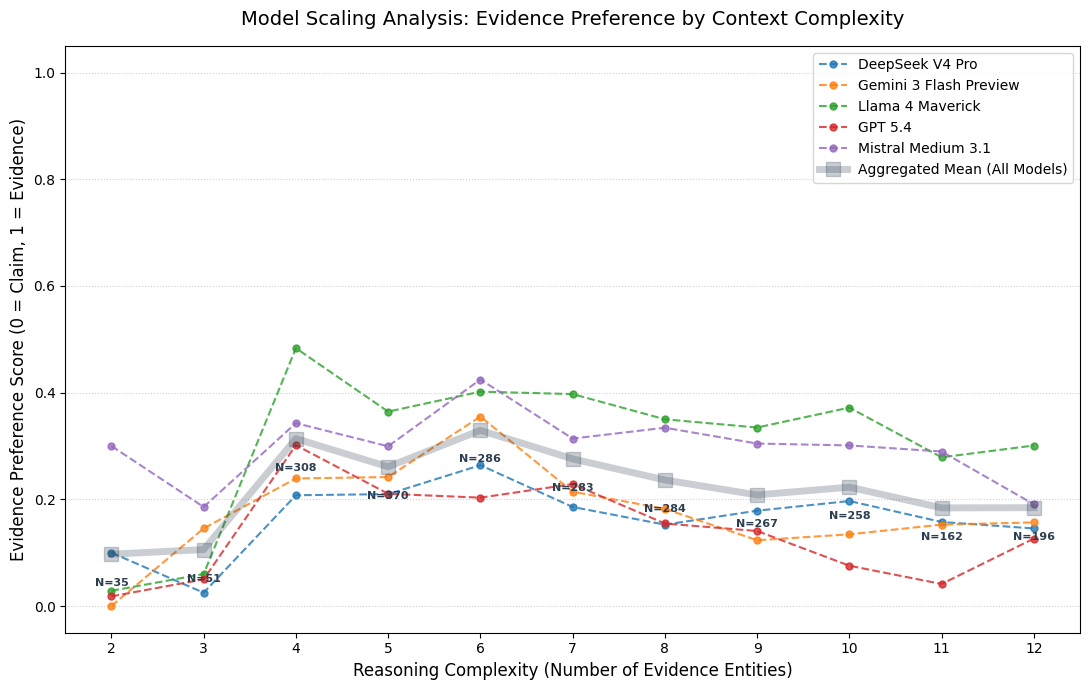

In [198]:
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict

def plot_individual_and_mean_complexity(model_results_dict, dataset_list):
    """
    Plots individual model lines alongside a thick, semi-transparent 
    aggregated mean across all models.
    
    Args:
        model_results_dict: Dict[str, Dict[str, Dict]] -> {"Model Name": results_dict}
        dataset_list: List[Dict] -> The raw dataset to extract complexity (ID and Fake data)
    """
    # 1. Map ID to Complexity (number of entities in Fake data)
    id_to_complexity = {
        item['ID']: len(item.get('Fake data', [])) 
        for item in dataset_list
    }

    # Track scores per model to plot them individually
    # {model_name: {complexity_bucket: [scores]}}
    model_bucket_scores = defaultdict(lambda: defaultdict(list))
    
    # Track overall scores for the global mean
    # {complexity_bucket: [scores]}
    global_bucket_scores = defaultdict(list)

    # 2. Extract and Group Data
    for model_name, model_dict in model_results_dict.items():
        for sample_id, result_data in model_dict.items():
            if sample_id not in id_to_complexity:
                continue
            
            complexity = id_to_complexity[sample_id]
            responses = result_data.get('responses', [])
            if not responses:
                continue
            
            valid_responses = [
                r for r in responses 
                if 'judge_results' in r and r['judge_results'] is not None
            ]
            if not valid_responses:
                continue
            
            evidence_count = sum(
                1 for r in valid_responses 
                if r['judge_results'].get('classification', '').lower() == 'evidence'
            )
            score = evidence_count / len(valid_responses)
            
            # Store to both individual and global buckets
            model_bucket_scores[model_name][complexity].append(score)
            global_bucket_scores[complexity].append(score)

    # 3. Plotting Setup
    plt.figure(figsize=(11, 7))
    
    # Get all distinct complexities present across the dataset
    all_complexities = sorted(global_bucket_scores.keys())

    # 4. Plot Individual Model Trends
    # Using a distinct color palette for readability
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
    
    for idx, (model_name, buckets) in enumerate(model_bucket_scores.items()):
        model_sorted_comps = sorted(buckets.keys())
        model_means = [np.mean(buckets[c]) for c in model_sorted_comps]
        
        plt.plot(
            model_sorted_comps, model_means,
            marker='o', markersize=5, linestyle='--', linewidth=1.5,
            color=colors[idx % len(colors)], label=model_name, alpha=0.8
        )

    # 5. Plot the Aggregated Global Mean (Thick & Transparent Background)
    global_means = [np.mean(global_bucket_scores[c]) for c in all_complexities]
    
    plt.plot(
        all_complexities, global_means,
        marker='s', markersize=10, linestyle='-', linewidth=5,
        color='#2c3e50', alpha=0.25, label='Aggregated Mean (All Models)'
    )

    # Add sample size text labels for the global data buckets
    for i, comp in enumerate(all_complexities):
        n = len(global_bucket_scores[comp])
        plt.text(comp, global_means[i] - 0.06, f"N={n}", ha='center', fontsize=8, color='#2c3e50', weight='bold')

    # Styling for an ACL appendix
    plt.title("Model Scaling Analysis: Evidence Preference by Context Complexity", fontsize=14, pad=15)
    plt.xlabel("Reasoning Complexity (Number of Evidence Entities)", fontsize=12)
    plt.ylabel("Evidence Preference Score (0 = Claim, 1 = Evidence)", fontsize=12)
    plt.xticks(all_complexities)
    plt.ylim(-0.05, 1.05)
    plt.grid(axis='y', linestyle=':', alpha=0.6)
    plt.legend(loc='upper right', frameon=True, shadow=False, facecolor='white')
    
    plt.tight_layout()
    plt.show()

# Usage:
# Wrap your separate results in a named dictionary before calling
models_to_sweep = {
    "DeepSeek V4 Pro": deepseek_baseline_res,
    "Gemini 3 Flash Preview": google_baseline_res,
    "Llama 4 Maverick": meta_baseline_res,
    "GPT 5.4": gpt_baseline_res,
    "Mistral Medium 3.1": mistral_baseline_res
}

plot_individual_and_mean_complexity(models_to_sweep, question_data)

In [204]:
def _draw_plot(model_bucket_scores, global_bucket_scores, title, ylabel):
    plt.figure(figsize=(11, 7))
    all_complexities = sorted(global_bucket_scores.keys())
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
    
    # 1. Model Lines
    for idx, (model_name, buckets) in enumerate(model_bucket_scores.items()):
        comps = sorted(buckets.keys())
        means = [np.mean(buckets[c]) for c in comps]
        plt.plot(comps, means, marker='o', linestyle='--', label=model_name, color=colors[idx % len(colors)], alpha=0.7)

    # 2. Aggregated Mean
    global_means = [np.mean(global_bucket_scores[c]) for c in all_complexities]
    plt.plot(all_complexities, global_means, marker='s', markersize=12, linewidth=6, color='#2c3e50', alpha=0.2, label='Global Trend')

    # 3. Sample Size Labels (showing how many reached 'stable' status)
    for i, comp in enumerate(all_complexities):
        n = len(global_bucket_scores[comp])
        plt.text(comp, global_means[i] + 0.05, f"n={n}", ha='center', fontsize=8, weight='bold')

    plt.title(title, fontsize=14, pad=15)
    plt.xlabel("Reasoning Complexity (# of Entities)", fontsize=12)
    plt.ylabel(ylabel, fontsize=12)
    plt.xticks(all_complexities)
    plt.ylim(-0.05, 1.05)
    plt.grid(axis='y', linestyle=':', alpha=0.6)
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

In [218]:
def plot_stable_evidence_vs_complexity(model_results_dict, dataset_list):
    id_to_complexity = {item['ID']: len(item.get('Fake data', [])) for item in dataset_list}
    model_bucket_scores = defaultdict(lambda: defaultdict(list))
    global_bucket_scores = defaultdict(list)

    for model_name, model_dict in model_results_dict.items():
        for sample_id, result_data in model_dict.items():
            if sample_id not in id_to_complexity: continue
            complexity = id_to_complexity[sample_id]
            responses = result_data.get('responses', [])
            
            valid_res = [r for r in responses if r.get('judge_results')]
            if not valid_res: continue
            
            # Count how many iterations resulted in "Evidence"
            ev_count = sum(1 for r in valid_res if r['judge_results'].get('classification', '').lower() == 'evidence')
            
            # STABLE PREFERENCE CHECK: 
            # 1 if the model was consistent (>= 80% evidence), 0 otherwise.
            is_stable = 1 if (ev_count / len(valid_res)) >= 0.8 else 0
            
            model_bucket_scores[model_name][complexity].append(is_stable)
            global_bucket_scores[complexity].append(is_stable)

    _draw_plot(model_bucket_scores, global_bucket_scores, 
               title="Reliability Scaling: Stable Evidence Preference (≥4/5)",
               ylabel="% of Samples with Stable Evidence Preference")

In [211]:
def plot_ack_vs_complexity(model_results_dict, dataset_list):
    id_to_complexity = {item['ID']: len(item.get('Fake data', [])) for item in dataset_list}
    model_bucket_scores = defaultdict(lambda: defaultdict(list))
    global_bucket_scores = defaultdict(list)

    for model_name, model_dict in model_results_dict.items():
        for sample_id, result_data in model_dict.items():
            if sample_id not in id_to_complexity: continue
            complexity = id_to_complexity[sample_id]
            responses = result_data.get('responses', [])
            
            valid_res = [r for r in responses if r.get('judge_results')]
            if not valid_res: continue
            
            # Mean Acknowledgment Rate for this sample
            ack_count = sum(1 for r in valid_res if r['judge_results'].get('conflict_acknowledged', False))
            ack_rate = ack_count / len(valid_res)
            
            model_bucket_scores[model_name][complexity].append(ack_rate)
            global_bucket_scores[complexity].append(ack_rate)

    _draw_plot(model_bucket_scores, global_bucket_scores, 
               title="Conflict Detection Scaling: Acknowledgment Rate",
               ylabel="Mean Acknowledgment Score (0-1)")

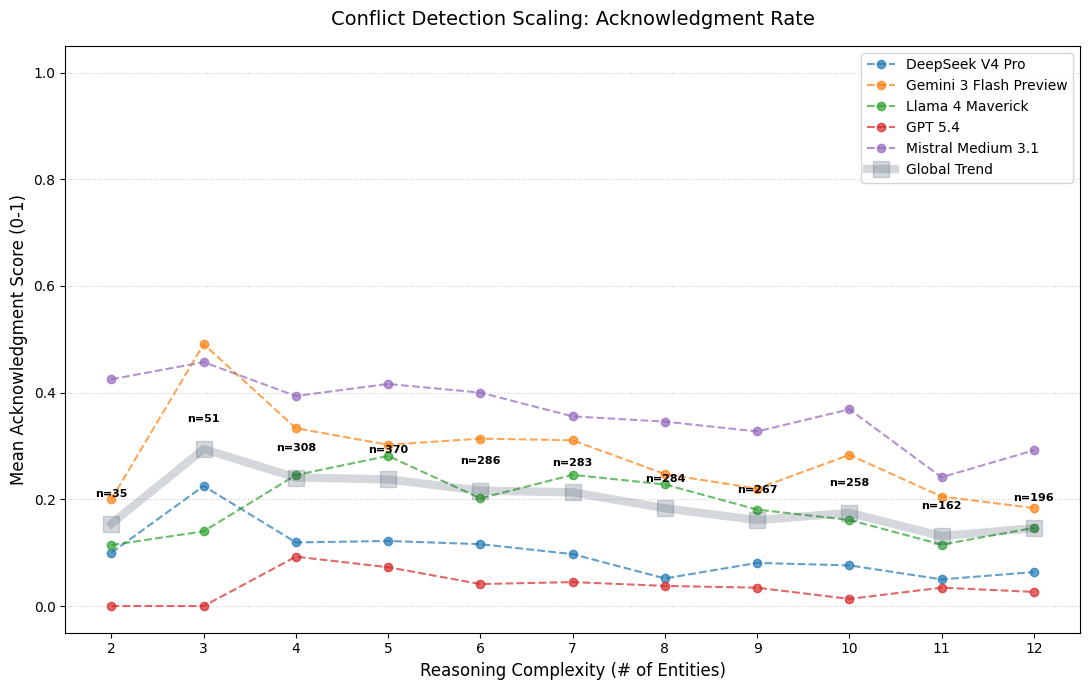

In [219]:
plot_ack_vs_complexity(models_to_sweep, question_data)

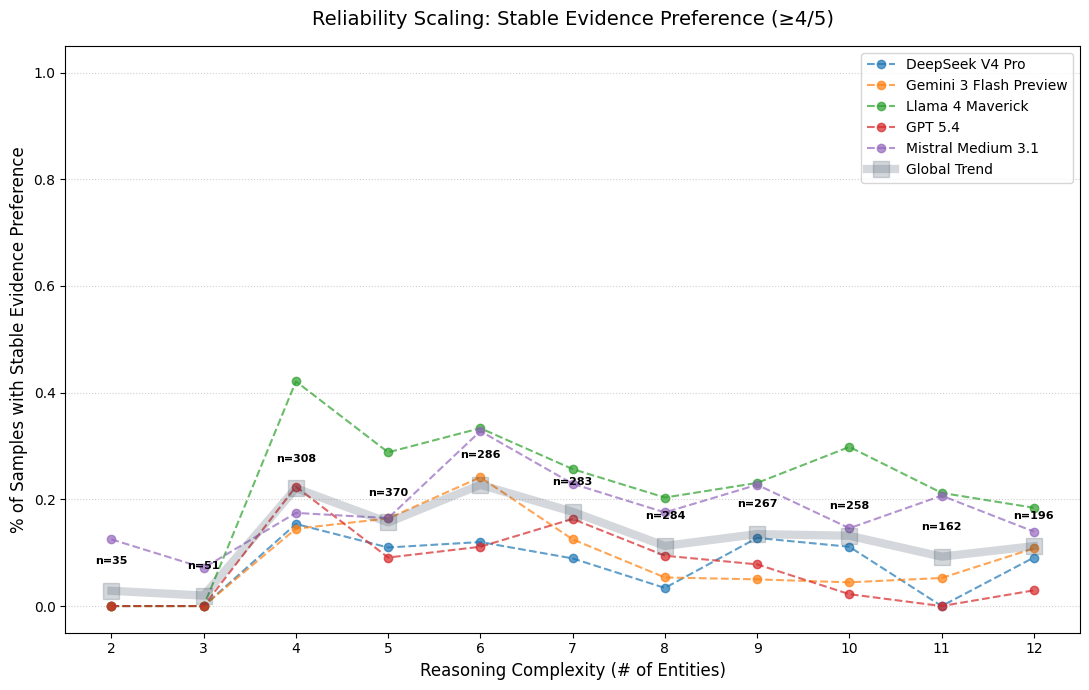

In [220]:
plot_stable_evidence_vs_complexity(models_to_sweep, question_data)

In [214]:
import pandas as pd
from collections import defaultdict
import numpy as np

def generate_strategy_performance_table(model_results_dict, dataset_list):
    """
    Generates a summary table of ACK Rate and Evidence Preference per Strategy,
    averaged across all models.
    """
    # 1. Map ID to its Strategy
    id_to_strategy = {item['ID']: item['Selected strategy'] for item in dataset_list}
    
    # 2. Aggregator for statistics
    # {strategy: {'ack_scores': [], 'pref_scores': []}}
    strat_stats = defaultdict(lambda: {'ack_scores': [], 'pref_scores': []})

    # 3. Process all models and samples
    for model_name, model_dict in model_results_dict.items():
        for sample_id, result_data in model_dict.items():
            if sample_id not in id_to_strategy:
                continue
            
            strategy = id_to_strategy[sample_id]
            responses = result_data.get('responses', [])
            
            valid_res = [r for r in responses if r.get('judge_results')]
            if not valid_res:
                continue
            
            # Calculate rates for this specific sample/model pair
            ack_count = sum(1 for r in valid_res if r['judge_results'].get('conflict_acknowledged', False))
            ev_count = sum(1 for r in valid_res if r['judge_results'].get('classification', '').lower() == 'evidence')
            
            ack_rate = ack_count / len(valid_res)
            pref_rate = ev_count / len(valid_res)
            
            strat_stats[strategy]['ack_scores'].append(ack_rate)
            strat_stats[strategy]['pref_scores'].append(pref_rate)

    # 4. Build the DataFrame
    table_data = []
    for strategy, scores in strat_stats.items():
        avg_ack = np.mean(scores['ack_scores']) * 100
        avg_pref = np.mean(scores['pref_scores']) * 100
        sample_count = len(scores['ack_scores']) # models * samples
        
        table_data.append({
            "Strategy": strategy,
            "ACK Rate (%)": round(avg_ack, 1),
            "Ev. Preference (%)": round(avg_pref, 1),
            "N (Eval. Count)": sample_count
        })

    df = pd.DataFrame(table_data)
    
    # Sort by ACK Rate to show which strategies are easiest to detect
    df = df.sort_values(by="ACK Rate (%)", ascending=False).reset_index(drop=True)
    
    print("\n--- Strategy Performance Summary (Averaged Across Models) ---")
    print(df.to_string(index=False))
    
    return df

# Usage:
df_stats = generate_strategy_performance_table(models_to_sweep, question_data)

# For your ACL paper, you can run this to get the LaTeX code directly:
# print(df_stats.to_latex(index=False))


--- Strategy Performance Summary (Averaged Across Models) ---
                 Strategy  ACK Rate (%)  Ev. Preference (%)  N (Eval. Count)
   COMPARATIVE_DIFFERENCE          37.6                43.9              237
        EXTREME_NUMERICAL          31.2                59.1              256
            TOP_K_RANKING          19.7                34.1              241
              COUNT_TOTAL          18.6                 7.6              217
         EXTREME_TEMPORAL          18.5                29.7              230
   FILTER_COUNT_NUMERICAL          18.5                24.7              217
CATEGORICAL_FILTER_LOOKUP          15.8                13.3              218
           FREQUENCY_MODE          15.7                16.8              237
    FILTER_COUNT_TEMPORAL          14.0                 9.9              243
         UNIQUE_DIVERSITY          13.1                17.9              231
              AGGREGATION          11.2                 5.9              173


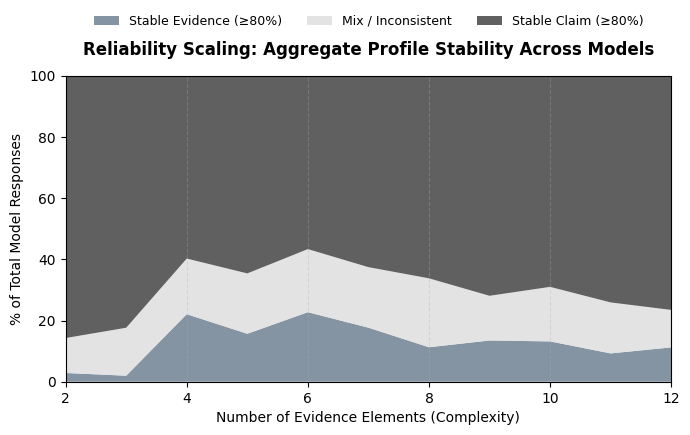

In [217]:
from collections import defaultdict
import matplotlib.pyplot as plt

def plot_combined_stable_behavior_vs_complexity(model_results_dict, dataset_list):
    # Map sample ID to number of evidence items (complexity axis)
    id_to_complexity = {item['ID']: len(item.get('Fake data', [])) for item in dataset_list}
    
    # Global tracker across all models: complexity -> category -> total_sample_count
    global_bucket_counts = defaultdict(lambda: {'stable_evidence': 0, 'stable_claim': 0, 'mix': 0})

    for model_name, model_dict in model_results_dict.items():
        for sample_id, result_data in model_dict.items():
            if sample_id not in id_to_complexity: 
                continue
            
            complexity = id_to_complexity[sample_id]
            responses = result_data.get('responses', [])
            
            valid_res = [r for r in responses if r.get('judge_results')]
            if not valid_res: 
                continue
            
            total_runs = len(valid_res)
            ev_count = sum(1 for r in valid_res if r['judge_results'].get('classification', '').lower() == 'evidence')
            claim_count = sum(1 for r in valid_res if r['judge_results'].get('classification', '').lower() == 'claim')
            
            # Classify macro-behavior profile for this specific model-sample pair
            if (ev_count / total_runs) >= 0.8:
                category = 'stable_evidence'
            elif (claim_count / total_runs) >= 0.8:
                category = 'stable_claim'
            else:
                category = 'mix'
                
            global_bucket_counts[complexity][category] += 1

    if not global_bucket_counts:
        print("No valid evaluation data found to plot.")
        return

    # Sort complexities for the X-axis
    complexities = sorted(global_bucket_counts.keys())
    
    stable_ev_pct = []
    mix_pct = []
    stable_claim_pct = []
    
    for comp in complexities:
        counts = global_bucket_counts[comp]
        total = counts['stable_evidence'] + counts['stable_claim'] + counts['mix']
        
        if total > 0:
            stable_ev_pct.append((counts['stable_evidence'] / total) * 100)
            mix_pct.append((counts['mix'] / total) * 100)
            stable_claim_pct.append((counts['stable_claim'] / total) * 100)
        else:
            stable_ev_pct.append(0)
            mix_pct.append(0)
            stable_claim_pct.append(0)

    # Setup a single, clean plot
    fig, ax = plt.subplots(figsize=(7, 4.5))
    
    # Neutral, academic palette (No green/red bias)
    # Slate Blue-Gray for Evidence, Light Gray for Inconsistent, Dark Charcoal for Claim
    neutral_colors = ['#778899', '#e0e0e0', '#4f4f4f']
    
    ax.stackplot(complexities, stable_ev_pct, mix_pct, stable_claim_pct,
                 labels=['Stable Evidence (≥80%)', 'Mix / Inconsistent', 'Stable Claim (≥80%)'],
                 colors=neutral_colors, alpha=0.9)
    
    # Styling
    ax.set_title("Reliability Scaling: Aggregate Profile Stability Across Models", fontsize=12, fontweight='bold', pad=15)
    ax.set_xlabel("Number of Evidence Elements (Complexity)", fontsize=10)
    ax.set_ylabel("% of Total Model Responses", fontsize=10)
    
    ax.set_xlim(min(complexities), max(complexities))
    ax.set_ylim(0, 100)
    ax.grid(axis='x', linestyle='--', alpha=0.3)
    
    # Legend placed cleanly at the top
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.12), ncol=3, frameon=False, fontsize=9)
    
    plt.tight_layout()
    plt.show()
plot_combined_stable_behavior_vs_complexity(models_to_sweep, question_data)